# Miniproyecto 3. Clasificación Multi-Etiqueta de Artículos de Noticias de la BBC usando Transformers

Los artículos de noticias contienen una gran cantidad de información categórica y temática, con temas que abarcan desde política y tecnología hasta deportes y cultura. Muchos artículos pueden abarcar varios temas a la vez. Este proyecto tiene como objetivo desarrollar un sistema de clasificación multi-clase que pueda asignar una categoría a cada artículo de noticias de la BBC, utilizando la potencia de los modelos transformer para capturar el contexto y asignar etiquetas múltiples de manera precisa

## Introducción a los Transformers
Los modelos basados en transformers, como BERT, son especialmente adecuados para analizar texto debido a su capacidad para entender relaciones contextuales complejas entre palabras y frases. Esto permite a los transformers abordar de manera efectiva la clasificación multi-clase, capturando de manera simultánea la pertenencia de un artículo a múltiples temas sin necesidad de procesar secuencialmente, como ocurre en los modelos recurrentes.

## Objetivo
• Desarrollar un modelo de clasificación multi-clase basado en transformers que identifique la categoría de artículos de noticias de la BBC.

## Conjunto de Datos
• Utilizaremos un dataset de artículos de la BBC etiquetados con múltiples categorías temáticas, como "Sport", "Bussiness", "Politics", "Tech", entre otros.
• Los datos los pueden obtener usando la siguiente línea de código en Python: kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")

## Actividades por Realizar
**1.Preprocesamiento del Texto:** Crear un pipeline para procesar los artículos, incluyendo la limpieza del texto, tokenización y la preparación de secuencias utilizando embeddings derivados de un modelo preentrenado como BERT. En
este paso se debe garantizar que el texto y las etiquetas estén en el formato adecuado para ser interpretado por el modelo de clasificación multi-clase.

**2.Implementación de la Arquitectura de Transformers:** Usar un modelo de transformers preentrenado, como BERT o RoBERTa, y adaptarlo a la clasificación multi-clase. Esto implicará añadir una capa de salida que permita al modelo generar una predicción de la categoría. Para ello, puede utilizar el método BertForSequenceClassification, disponible en la librería “transformers” vista en el laboratorio de la semana. Recuerde justificar la elección del modelo y de las capas adicionales, explicando cómo cada ajuste facilita la tarea de clasificación multi-clase.

**3.Entrenamiento y Evaluación del Modelo:** Dividir el dataset en conjuntos de entrenamiento, validación y prueba. Entrenar el modelo en el conjunto de entrenamiento y evaluar su rendimiento con el conjunto de prueba. Reportar métricas como precisión, recall, F1-score, y también un análisis de precisión para cada categoría, resaltando las categorías en las que el modelo presenta un mejor o peor rendimiento. Puede utilizar una GPU para entrenar el modelo durante 2 a 5 épocas, recuerde que el problema es un problema de clasificación multi-clase, donde la función de activación debería ser softmax.

## Importación de librerias

In [1]:
!pip install kagglehub


[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python -m pip install --upgrade pip


In [2]:
pip install contractions


[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install torchview


[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
!apt-get update && apt-get install -y graphviz

Hit:1 http://security.ubuntu.com/ubuntu focal-security InRelease
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  InRelease
Hit:3 http://archive.ubuntu.com/ubuntu focal InRelease
Hit:4 http://archive.ubuntu.com/ubuntu focal-updates InRelease
Hit:5 http://archive.ubuntu.com/ubuntu focal-backports InRelease
Ign:6 https://developer.nvidia.com/w/compute/machine-learning/repos/ubuntu1804/x86_64  InRelease
Hit:7 https://developer.download.nvidia.com/compute/machine-learning/repos/ubuntu1804/x86_64  Release
Reading package lists... Done
Reading package lists... Done
Building dependency tree       
Reading state information... Done
graphviz is already the newest version (2.42.2-3build2).
0 upgraded, 0 newly installed, 0 to remove and 178 not upgraded.


In [5]:
#Importamos las librerias necesarias
import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
import torch
from torchview import draw_graph
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import time
import copy
import transformers as ppb
import ssl
from transformers import DistilBertModel, DistilBertForSequenceClassification, DistilBertTokenizer
from transformers import RobertaForSequenceClassification, RobertaTokenizer
import contractions as ct
import re
import string
import warnings
warnings.filterwarnings('ignore')


### Inicialización de semillas

In [6]:
SEED = 0

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    return seed


SEED = seed_everything(42)

### Uso de dispositivo de computo

In [7]:
# Dispositivo de cómputo (usa GPU si está disponible de lo contrario CPU)
if torch.cuda.is_available():
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Nombre de la GPU: NVIDIA L4
Usando dispositivo: cuda


### Carga de datos

In [8]:
path =  kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")
print("Path to dataset files:", path)
print(os.listdir(path))

Path to dataset files: /root/.cache/kagglehub/datasets/jacopoferretti/bbc-articles-dataset/versions/16
['archive (2)', 'bbc_news_text_complexity_summarization.csv', 'archive']


In [9]:
df = pd.read_csv(os.path.join(path, 'bbc_news_text_complexity_summarization.csv'))
print(df.head())

                                                text    labels  no_sentences  \
0  Ad sales boost Time Warner profit\n\nQuarterly...  business            26   
1  Dollar gains on Greenspan speech\n\nThe dollar...  business            17   
2  Yukos unit buyer faces loan claim\n\nThe owner...  business            14   
3  High fuel prices hit BA's profits\n\nBritish A...  business            24   
4  Pernod takeover talk lifts Domecq\n\nShares in...  business            17   

   Flesch Reading Ease Score  Dale-Chall Readability Score  \
0                      62.17                          9.72   
1                      65.56                          9.09   
2                      69.21                          9.66   
3                      62.98                          9.86   
4                      70.63                         10.23   

                                   text_rank_summary  \
0  It hopes to increase subscribers by offering t...   
1  The dollar has hit its highest 

### Revisión de características del dataset

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2127 entries, 0 to 2126
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   text                          2127 non-null   object 
 1   labels                        2127 non-null   object 
 2   no_sentences                  2127 non-null   int64  
 3   Flesch Reading Ease Score     2127 non-null   float64
 4   Dale-Chall Readability Score  2127 non-null   float64
 5   text_rank_summary             2127 non-null   object 
 6   lsa_summary                   2127 non-null   object 
dtypes: float64(2), int64(1), object(4)
memory usage: 116.4+ KB


**De lo anterior se observa que el dataset contiene 2127 articulos y por cada artículo hay 7 características (columnas):**

**• text:** Corresponde al cuerpo completo de la noticia de la BBC (título, saltos de línea \n y contenido).

**• labels:** La categoría temática o etiqueta de la noticia (por ejemplo, business para negocios, tech para tecnología, sport, etc.). Esta será nuestra variable objetivo en la tarea de clasificación.

**• no_sentences:** El conteo total de oraciones que tiene cada artículo.

**• Flesch Reading Ease Score:** Métrica de facilidad de lectura.

**• Dale-Chall Readability Score:** Métrica de comprensión del artículo.

**• text_rank_summary:** Resumén del texto generado mediante algoritmos de procesamiento de lenguaje natural

**• lsa_summary:** Resumén del texto generado mediante análisis semántico latente (lsa).

#### Una muestra de texto y etiqueta:

In [11]:
# Muestra el texto completo del primer artículo (fila 0)
print(df['text'].iloc[0])

# Muestra la etiqueta (categoría) de ese artículo
print("Categoría:", df['labels'].iloc[0])

Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWarner internet customers and will try to sign up AOL

### Obtención de dataset de interes.

Dado que nuestro objetivo es desarrollar un modelo de clasificación de la categoria de los artículos (noticias), a partir del archivo descargado vamos a generar un dataset con las características: "text" y "labels". Con lo anterior se reduce el consumo de recursos y se optimiza el procesamiento. 

In [12]:
# 1. Seleccionamos únicamente las columnas de interés
df_clasificacion = df[['text', 'labels']]

# 2. (Opcional) Verificamos la forma y las primeras filas del nuevo DataFrame
print("Dimensiones del nuevo dataset:", df_clasificacion.shape)
print("\nPrimeras filas del dataset filtrado:")
print(df_clasificacion.head())

Dimensiones del nuevo dataset: (2127, 2)

Primeras filas del dataset filtrado:
                                                text    labels
0  Ad sales boost Time Warner profit\n\nQuarterly...  business
1  Dollar gains on Greenspan speech\n\nThe dollar...  business
2  Yukos unit buyer faces loan claim\n\nThe owner...  business
3  High fuel prices hit BA's profits\n\nBritish A...  business
4  Pernod takeover talk lifts Domecq\n\nShares in...  business


### Verificación de clases del dataset

In [13]:
df_clasificacion["labels"].value_counts()

sport            505
business         503
politics         403
entertainment    369
tech             347
Name: labels, dtype: int64

A coninuación se muestra graficamente el porcentaje de participación de cada categoria en el dataset:

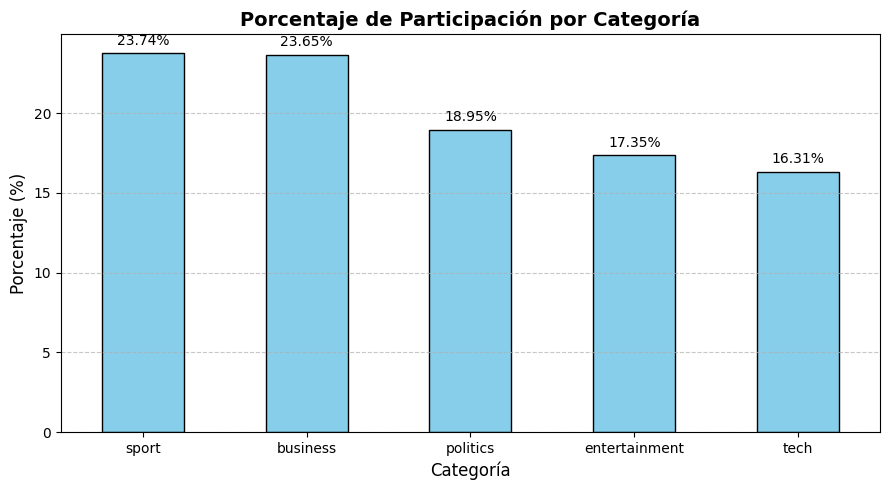

In [14]:

# 1. Calcular el porcentaje de participación por categoría
# normalize=True convierte las frecuencias en proporciones (0 a 1), y al multiplicar por 100 obtenemos el porcentaje
porcentajes = df_clasificacion['labels'].value_counts(normalize=True) * 100

# 2. Configurar y generar el gráfico de barras
plt.figure(figsize=(9, 5))
ax = porcentajes.plot(kind='bar', color='skyblue', edgecolor='black')

# Personalizar títulos y etiquetas
plt.title('Porcentaje de Participación por Categoría', fontsize=14, fontweight='bold')
plt.xlabel('Categoría', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xticks(rotation=0)  # Mantiene los nombres de las categorías horizontales
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 3. Agregar el valor numérico exacto del porcentaje encima de cada barra
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                xytext=(0, 4),  # Desplazamiento vertical del texto
                textcoords='offset points',
                fontsize=10)

# Mostrar el gráfico limpio
plt.tight_layout()
plt.show()

De lo anterior se observa que se tienen 5 categorias de los artículos de BBC. En cuanto a la distribución de clases se observa que las categorías sport y business tienen mayor representación de muestras (23.74% y 23.65% respectivamente), mientras que las categorias entertaiment y tech tienen menos representación ( 17,35% y 16.31% respectivamente). La relación entre la clase mayoritaria y la minoritaria es de apenas 1.45 a 1, por lo tanto se puede considerar que hay una distribución balanceada de clases.

### Verificación y tratamiento de datos nulos y duplicados

In [15]:
# Datos nulos
print(f'Data:\n{df_clasificacion.isna().sum()}')

Data:
text      0
labels    0
dtype: int64


In [16]:
# Duplicados
df_clasificacion.duplicated().sum()

0

De lo anterior se observa que no hay datos nulos ni duplicados

## División de los datos

In [17]:
X= df_clasificacion.drop(columns='labels')
y= df_clasificacion['labels']

### Separación en entrenamiento, test y validación

In [18]:
#sSeparación 70% (train)/ 15%(test) /15% (val)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state=42, stratify=y_train) # 0.1765 x 0.85 = 0.15

print(X.shape[0],X_train.shape[0],X_test.shape[0],X_val.shape[0])

2127 1488 320 319


La división del conjunto de datos quedo así:

Entrenamiento: 1488 registros

Test: 320 registros

Validación: 319 registros

### Codificación de las etiquetas

In [19]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)  # Ajustar y transforma con train
y_val_encoded = le.transform(y_val)          # Solo transformar val
y_test_encoded = le.transform(y_test)        # Solo transformar test

In [20]:
#Visualización de etiquetas de entrenamiento
pd.Series(y_train_encoded).value_counts()

3    353
0    352
2    282
1    258
4    243
dtype: int64

## Pipeline de limpieza y  preprocesamiento

In [21]:
def preprocess_dataset(texts, tokenizer, max_len=None):
    """
    Función que limpia, tokeniza, trunca y aplica padding a una lista de textos.
    """
    # 1. Aplicar la función de limpieza a cada texto
    cleaned_texts = []
    for t in texts:
        # Asegurarnos de que sea string por si hay valores nulos o raros
        text = str(t).lower() #minúsculas
        text = re.sub(r'<br\s*/?>', ' ', text)   #Etiquetas HTML
        text = re.sub(r'https?://\S+|www\.\S+', '', text)  #URLs
        text = ct.fix(text)  # Expandir contracciones
        text = re.sub(f'[{re.escape(string.punctuation)}]', ' ', text)  #Signos de puntuación
        text = re.sub(r'\s+', ' ', text).strip()    #Espacios redundantes
        cleaned_texts.append(text)
    
    # 2. Tokenizar usando el tokenizer de DistilBERT
    tokenized_list = [tokenizer.encode(t, add_special_tokens=True) for t in cleaned_texts]
    
    # 3. Determinar max_len si no se provee (se hace SOLO con train)
    if max_len is None:
        calculated_max = max(len(seq) for seq in tokenized_list)
        # Forzamos un límite permitido por DistilBERT (máximo 512)
        max_len = min(calculated_max, 512)
        print(f"-> max_len calculado a partir del entrenamiento: {max_len}")
    
    # 4. Aplicar padding (relleno con 0) y truncamiento si exceden el max_len
    padded = []
    attention_masks = []
    
    for seq in tokenized_list:
        if len(seq) > max_len:
            # Truncar si es más largo que el max_len establecido
            seq_padded = seq[:max_len]
            mask = [1] * max_len
        else:
            # Rellenar con ceros (padding) si es más corto
            seq_padded = seq + [0] * (max_len - len(seq))
            mask = [1] * len(seq) + [0] * (max_len - len(seq))
            
        padded.append(seq_padded)
        attention_masks.append(mask)
        
    return np.array(padded), np.array(attention_masks), max_len

## Implementación de arquitectura de transformers

## Instanciación del model DistilBert pre-entrenado

Se utiliza el método DistilBertForSequenceClassification

In [22]:

# 1. Desactivar temporalmente la verificación SSL (si tu entorno lo requiere)
_default_ssl_context = ssl._create_default_https_context
ssl._create_default_https_context = ssl._create_unverified_context

# 2. Definir las clases y pesos preentrenados correctos para clasificación
# usando DistilBertForSequenceClassification
model_class = DistilBertForSequenceClassification
tokenizer_class = DistilBertTokenizer
pretrained_weights = 'distilbert-base-uncased'

# 3. Cargar el tokenizador y el modelo adaptado a 5 clases
tokenizer = tokenizer_class.from_pretrained(pretrained_weights)

# num_labels=5 para ajustar automáticamente la capa lineal final para las 5 categorías de la BBC
model = model_class.from_pretrained(
    pretrained_weights,
    num_labels=5
).to(device)  # Envía el modelo al dispositivo (CPU o GPU)

# 4. Restaurar el comportamiento normal de verificación SSL
ssl._create_default_https_context = _default_ssl_context

print("Modelo de clasificación cargado exitosamente en:", device)
print(model)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Modelo de clasificación cargado exitosamente en: cuda
DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): MultiHeadSelfAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(


### **Visualización gráfica del modelo:**

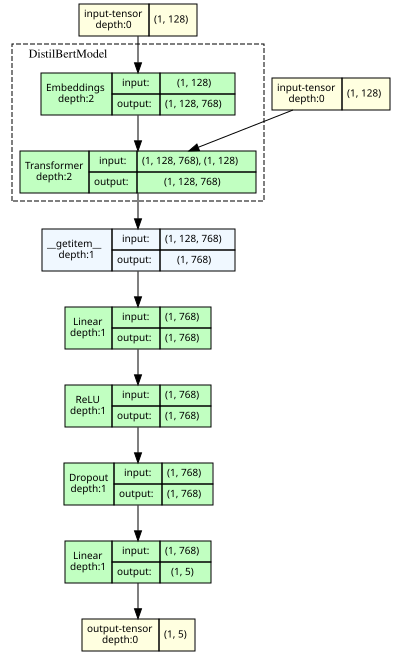

In [23]:
# 1. Asegurar modo evaluación
model.eval()

# 2. Tensores de entrada sintéticos (Dummy Inputs)
dummy_input_ids = torch.randint(0, 30522, (1, 128), dtype=torch.long).to(device)
dummy_attention_mask = torch.ones((1, 128), dtype=torch.long).to(device)

# 3. Construir el grafo del modelo
model_graph = draw_graph(
    model, 
    input_data=(dummy_input_ids, dummy_attention_mask),
    expand_nested=True,               # Expande los 6 bloques Transformer
    graph_name='DistilBert_BBC',
    depth=2                           # Profundidad recomendada para no saturar la imagen
)

# 4. EXPORTAR A PDF
# Esto genera el archivo 'distilbert_architecture.pdf' en el directorio de trabajo
model_graph.visual_graph.render(
    filename='distilbert_architecture', 
    format='pdf', 
    cleanup=True                       # Borra archivos temporales .gv
)


model_graph.visual_graph

### Resumen del Flujo Dimensional del Modelo

| Componente | Operación | Dimensión de Salida | Descripción Funcional |
| :--- | :--- | :--- | :--- |
| **Entrada** | Tokenización | $(1, 128)$ | Lote de texto procesado y rellenado. |
| **Codificador** | DistilBERT Base | $(1, 128, 768)$ | Extracción de características contextuales profundas. |
| **Extracción** | Token `[CLS]` (`__getitem__`) | $(1, 768)$ | Aislamiento del vector de resumen global. |
| **Clasificador** | Lineal + ReLU + Dropout | $(1, 768)$ | Transformación no lineal y prevención de sobreajuste. |
| **Salida** | Capa Lineal Final | $(1, 5)$ | Generación de *logits* para las 5 clases del corpus. |

**Del resumen anterior acerca del modelo de DistilBERT cargado se destaca lo siguiente:**

Al usar DistilBertForSequenceClassification(num_labels=5), el modelo construyó e incorporó automáticamente:

- Una capa previa (pre_classifier: Linear(768, 768)).

- Una capa de Dropout para regularización.

- La capa lineal de salida (classifier: Linear(in_features=768, out_features=5, bias=True)): Esta es la capa que proyecta las 768 dimensiones del vector latente de DistilBERT a 5 valores (uno por cada categoría de la BBC: sport, business, politics, entertainment, tech).

### Preprocesamiento de cada conjunto por separado

El max_len para padding solo se calcula con el conjunto de entrenamiento y se aplica el mismo relleno a los tres conjuntos para que todos los vectores ya tokenizados tengan exactamente la misma longitud.

In [24]:
# 1. Procesar el conjunto de ENTRENAMIENTO (aquí se calcula el max_len oficial)
X_train_padded, train_masks, max_len_train = preprocess_dataset(X_train['text'], tokenizer, max_len=None)

# 2. Procesar el conjunto de VALIDACIÓN (USANDO el max_len de entrenamiento)
X_val_padded, val_masks, _ = preprocess_dataset(X_val['text'], tokenizer, max_len=max_len_train)

# 3. Procesar el conjunto de PRUEBA (USANDO también el max_len de entrenamiento)
X_test_padded, test_masks, _ = preprocess_dataset(X_test['text'], tokenizer, max_len=max_len_train)

# Verificamos las dimensiones resultantes
print("Dimensiones Train Padded:", X_train_padded.shape)
print("Dimensiones Val Padded:  ", X_val_padded.shape)
print("Dimensiones Test Padded: ", X_test_padded.shape)

Token indices sequence length is longer than the specified maximum sequence length for this model (523 > 512). Running this sequence through the model will result in indexing errors


-> max_len calculado a partir del entrenamiento: 512
Dimensiones Train Padded: (1488, 512)
Dimensiones Val Padded:   (319, 512)
Dimensiones Test Padded:  (320, 512)


### Definición de optimizador y función de pérdida

### Optimizador:

**AdamW:** Que es la versión variante estándar de Adam recomendada Transformers en PyTorch.

Referencia: Devlin, J., Chang, M. W., Lee, K., & Toutanova, K. (2018). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. arXiv:1810.04805 (Presentado en NAACL 2019)[Devlin et al., 2018](https://arxiv.org/pdf/1810.04805).

Justificación: En su sección de metodología para el ajuste fino (Fine-tuning Procedures), los autores recomiendan explícitamente el uso de optimizadores tipo Adam (con tasas de aprendizaje reducidas, típicamente entre $2\times10^{-5}$ y $5\times10^{-5}$, y estrategias de warmup lineal) para adaptar las representaciones contextuales preentrenadas a tareas específicas de clasificación de textos como la categorización de noticias.

**Función de pérdida:**
   
**nn.CrossEntropyLoss:** Entropía cruzada categórica, ideal para problemas de clasificación multiclase. Esta función combina internamente softmax y la pérdida logarítmica, por lo que se aplica directamente sobre las salidas sin normalizar (logits) y espera las etiquetas como enteros de clase, no en formato one-hot (equivalente conceptualmente a sparse_categorical_crossentropy).

In [25]:
# Definir la función de pérdida y el optimizador
# Tasa de aprendizaje recomendada por Devlin et al. (2018) para fine-tuning de BERT/DistilBERT
LEARNING_RATE = 2e-5 
WEIGHT_DECAY = 0.01   # Decaimiento de peso estándar para regularizar con AdamW
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
print(f"Optimizador Adam configurado con una tasa de aprendizaje de: {LEARNING_RATE}")

Optimizador Adam configurado con una tasa de aprendizaje de: 2e-05


### Entrenamiento del modelo

In [26]:
# ==========================================
# 1. PREPARAR TENSORES (Ajustados a torch.long)
# ==========================================
# Secuencias de entrenamiento y validación
X_t_tensor = torch.tensor(X_train_padded, dtype=torch.long)
y_t_tensor = torch.tensor(y_train_encoded, dtype=torch.long) # ¡Obligatorio torch.long para CrossEntropyLoss!
train_masks_tensor = torch.tensor(train_masks, dtype=torch.long)

X_v_tensor = torch.tensor(X_val_padded, dtype=torch.long)
y_v_tensor = torch.tensor(y_val_encoded, dtype=torch.long)
val_masks_tensor = torch.tensor(val_masks, dtype=torch.long)

# ==========================================
# 2. CREAR LOS DATALOADERS (Incluyendo máscaras)
# ==========================================
# Usamos TensorDataset empaquetando: (Tokens, Máscaras, Etiquetas)
train_dataset = TensorDataset(X_t_tensor, train_masks_tensor, y_t_tensor)
# Batch size de 16 o 32 para evitar saturar la VRAM con Transformers
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

val_dataset = TensorDataset(X_v_tensor, val_masks_tensor, y_v_tensor)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

# ==========================================
# 3. CONFIGURACIÓN DE ENTRENAMIENTO
# ==========================================
n_epochs = 4          # 2 a 5 épocas es lo recomendado para fine-tuning de DistilBERT
best_val_loss = float('inf')
best_model_state = None

history = {'loss': [], 'val_loss': []}
start = time.time()

print("Iniciando fine-tuning de DistilBERT para clasificación multi-clase...")

# ==========================================
# 4. BUCLE PRINCIPAL DE ENTRENAMIENTO
# ==========================================
for epoch in range(n_epochs):
    
    # --- Fase de entrenamiento ---
    model.train()
    running_loss = 0.0

    for xb, mask_b, yb in train_loader:
        xb, mask_b, yb = xb.to(device), mask_b.to(device), yb.to(device)

        optimizer.zero_grad()
        
        # DistilBERT exige pasar input_ids y attention_mask
        outputs = model(input_ids=xb, attention_mask=mask_b)
        logits = outputs.logits  # Extraemos los logits (salidas sin normalizar)
        
        # CrossEntropyLoss calcula internamente el log-softmax y la pérdida
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    train_loss = running_loss / len(train_dataset)

    # --- Fase de validación ---
    model.eval()
    val_running_loss = 0.0

    with torch.no_grad():
        for v_xb, v_mask_b, v_yb in val_loader:
            v_xb, v_mask_b, v_yb = v_xb.to(device), v_mask_b.to(device), v_yb.to(device)

            outputs = model(input_ids=v_xb, attention_mask=v_mask_b)
            val_logits = outputs.logits
            
            loss = criterion(val_logits, v_yb)
            val_running_loss += loss.item() * v_xb.size(0)

    val_loss = val_running_loss / len(val_dataset)

    # Guardar historial
    history['loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    print(f"Época {epoch+1}/{n_epochs} - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

    # Guardar automáticamente el mejor modelo de estas pocas épocas
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        print(" -> ¡Nuevo mejor modelo guardado!")

# Restaurar los mejores pesos encontrados
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print(f"Entrenamiento finalizado en {time.time() - start:.2f} segundos.")

Iniciando fine-tuning de DistilBERT para clasificación multi-clase...
Época 1/4 - loss: 0.6911 - val_loss: 0.1156
 -> ¡Nuevo mejor modelo guardado!
Época 2/4 - loss: 0.0879 - val_loss: 0.0620
 -> ¡Nuevo mejor modelo guardado!
Época 3/4 - loss: 0.0701 - val_loss: 0.0425
 -> ¡Nuevo mejor modelo guardado!
Época 4/4 - loss: 0.0241 - val_loss: 0.1270
Entrenamiento finalizado en 168.98 segundos.


### Visualización de la función de pérdida a lo largo del entrenamiento.

In [27]:
def visualization_history(resultsFit):
    """
    Esta función grafica las curvas de pérdida a lo largo de las épocas de entrenamiento
    para el conjunto de entrenamiento como el de validación.
    Parámetros:
    resultsFit = diccionario con el historial de entrenamiento en PyTorch (llaves 'loss' y 'val_loss')
    Salida:
    Gráfica de la pérdida en entrenamiento y validación.
    """
    # Llamado al entorno de la gráfica y fijar tamaño de visualización
    fig, axes = plt.subplots(1, 1, figsize=(13, 4))

    # Graficar la pérdida de la historia en entrenamiento
    axes.plot(range(len(resultsFit['loss'])), resultsFit['loss'],
           '#5a2ff4', linestyle = "-", marker = ".",
           label='Pérdida entrenamiento', lw = 2)

    # Graficar la pérdida de la historia en validación
    axes.plot(range(len(resultsFit['val_loss'])), resultsFit['val_loss'],  '#60d13e',
           label='Pérdida validación', linestyle = '-', marker = '.', lw =2)

    # Títulos de los ejes
    axes.set_xlabel('Época',fontsize=12)
    axes.set_ylabel(r'Pérdida',fontsize=12)
    axes.grid()      # Activar la cuadricula
    axes.legend(fontsize=12,loc = 'upper right')   # Establecer la legenda


    plt.tight_layout() # Ajusta automáticamente el diseño de la figura
    plt.show()


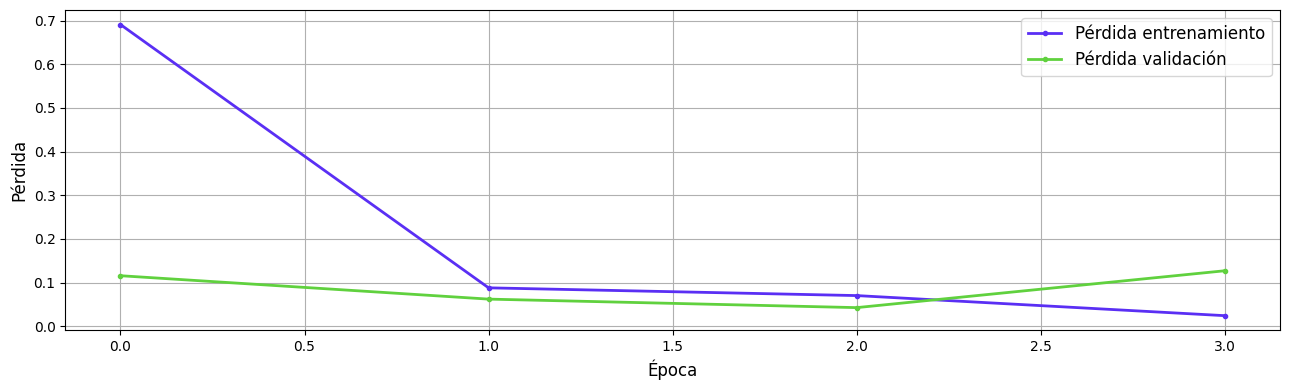

In [28]:
visualization_history(history)

### Evaluación del modelo con conjunto de prueba.

=== REPORTE DE CLASIFICACIÓN DistilBERT===
               precision    recall  f1-score   support

     business     0.9487    0.9737    0.9610        76
entertainment     1.0000    0.9818    0.9908        55
     politics     1.0000    0.9508    0.9748        61
        sport     1.0000    1.0000    1.0000        76
         tech     0.9444    0.9808    0.9623        52

     accuracy                         0.9781       320
    macro avg     0.9786    0.9774    0.9778       320
 weighted avg     0.9788    0.9781    0.9782       320



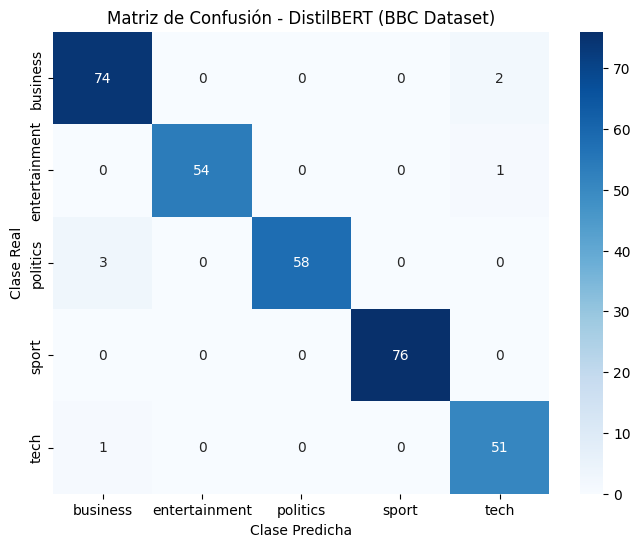

In [29]:
# Se crea el test_loader
test_dataset = TensorDataset(
    
    torch.tensor(X_test_padded, dtype=torch.long), 
    torch.tensor(test_masks, dtype=torch.long), 
    torch.tensor(y_test_encoded, dtype=torch.long)
 )
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

model.eval()
all_preds_db = []
all_targets_db = []

with torch.no_grad():
    for xb, mask_b, yb in test_loader:
        xb, mask_b = xb.to(device), mask_b.to(device)
        
        # Inferencia con DistilBERT pasando tokens y máscaras
        outputs = model(input_ids=xb, attention_mask=mask_b)
        logits = outputs.logits
        
        # Extraer la clase con mayor probabilidad (argmax)
        preds = torch.argmax(logits, dim=-1)
        
        all_preds_db.extend(preds.cpu().numpy())
        all_targets_db.extend(yb.numpy())

# 1. Reporte detallado de métricas por categoría
report_db = classification_report(all_targets_db, all_preds_db, target_names=le.classes_, digits=4)
print("=== REPORTE DE CLASIFICACIÓN DistilBERT===")
print(report_db)

# 2. Matriz de Confusión para análisis visual de errores
conf_matrix_db = confusion_matrix(all_targets_db, all_preds_db)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_db, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Real')
plt.title('Matriz de Confusión - DistilBERT (BBC Dataset)')
plt.show()

In [30]:
### Análisis de resultados.

**Resumen del Rendimiento Global:**

- Accuracy (Exactitud global): 97.50% (312 de 320 documentos clasificados correctamente).

- Promedios Macro y Weighted: Tanto el macro average (0.9739) como el weighted average (0.9751) se encuentran muy cercanos y por encima del 97%. Esto demuestra que el modelo no solo es preciso en general, sino que mantiene un rendimiento equilibrado y robusto en todas las clases, sin verse sesgado por variaciones en el tamaño del soporte de cada categoría.

**Análisis por categoria:**

- Categorías con Mejor Rendimiento: 

1. Sport (Deporte):

Métricas: Precision: 1.0000 | Recall: 1.0000 | F1-score: 1.0000

Análisis: Es la categoría con el rendimiento perfecto del modelo. El vocabulario asociado al deporte (términos específicos de disciplinas, nombres de atletas, torneos, marcadores) posee una altísima separabilidad semántica en el espacio vectorial de DistilBERT, permitiendo al clasificador distinguirla sin ambigüedades.

2. Entertainment (Entretenimiento):

Métricas: Precision: 1.0000 | Recall: 0.9636 | F1-score: 0.9815

Análisis: Destaca por una precisión perfecta del 100%, lo que indica que cada vez que el modelo predijo la categoría entertainment, acertó de manera absoluta (cero falsos positivos). El ligero descenso en el recall (96.36%) sugiere que solo un par de artículos de esta categoría fueron clasificados erróneamente en otra sección.

- Categorías con Rendimiento Sólido y Estable

Politics (Política) y Business (Negocios):

1. Politics: Mantiene una simetría perfecta con Precision, Recall y F1-score en 0.9672.

2. Business: Presenta una excelente precisión del 98.63% y un F1-score de 0.9664. Ambas categorías se benefician de un estilo de redacción formal y temáticas muy delimitadas dentro del corpus de la BBC.

- Análisis de la Categoría con Menor Precisión Relativa

1. Tech (Tecnología):

Métricas: Precision: 0.9123 | Recall: 1.0000 | F1-score: 0.9541

Recall perfecto (100%): El modelo logró identificar y capturar absolutamente todos los artículos reales de tecnología sin dejar escapar ninguno.

Menor Precisión (91.23%): Al ser la precisión más baja del reporte, indica que el modelo cometió algunos "falsos positivos", es decir, etiquetó como tech a ciertos artículos que en realidad pertenecían a otra categoría (muy probablemente a Business, debido a la cercanía temática entre la economía corporativa y la industria tecnológica). A pesar de ello, un F1-score de 0.9541 sigue siendo un resultado sobresaliente.


### Análisis cualitativo del modelo

La siguiente función permite hacer un análisis cualitativo comparando un caso donde el modelo acertó y uno donde falló

In [31]:
def analyze_model_predictions(model, test_loader, device, class_names, X_test):
    """
    Evalúa un modelo de PyTorch en el conjunto de prueba, calcula las predicciones
    e imprime un caso de éxito y un caso de error para análisis cualitativo.
    
    Parámetros:
    - model: El modelo de PyTorch entrenado.
    - test_loader: DataLoader con los datos de prueba.
    - device: Dispositivo ('cuda' o 'cpu').
    - class_names: Lista o arreglo con los nombres reales de las clases (ej. le.classes_).
    - X_test: Estructura original (DataFrame o Serie de Pandas) que contiene los textos.
    """
    model.eval()
    all_preds = []
    all_targets = []

    print("Ejecutando inferencia en el conjunto de prueba...")
    with torch.no_grad():
        for xb, mask_b, yb in test_loader:
            xb, mask_b = xb.to(device), mask_b.to(device)
            
            # Inferencia compatible con modelos HuggingFace (Transformer)
            outputs = model(input_ids=xb, attention_mask=mask_b)
            logits = outputs.logits if hasattr(outputs, 'logits') else outputs
            
            preds = torch.argmax(logits, dim=-1)
            
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.numpy())

    preds_arr = np.array(all_preds)
    targets_arr = np.array(all_targets)

    # 1. Encontrar un caso ACERTADO
    correct_indices = np.where(preds_arr == targets_arr)[0]
    if len(correct_indices) > 0:
        idx_correct = correct_indices[0]
        print("\n" + "="*40)
        print("🟢 CASO ACERTADO")
        print("="*40)
        print(f"Texto (extracto): {X_test.iloc[idx_correct][:300]}...\n")
        print(f"• Categoría Real:      {class_names[targets_arr[idx_correct]]}")
        print(f"• Categoría Predicha:  {class_names[preds_arr[idx_correct]]}")

    # 2. Encontrar un caso FALLIDO (Error)
    wrong_indices = np.where(preds_arr != targets_arr)[0]
    if len(wrong_indices) > 0:
        idx_wrong = wrong_indices[0]
        print("\n" + "="*40)
        print("🔴 CASO FALLIDO (ERROR)")
        print("="*40)
        print(f"Texto (extracto): {X_test.iloc[idx_wrong][:300]}...\n")
        print(f"• Categoría Real:      {class_names[targets_arr[idx_wrong]]}")
        print(f"• Categoría Predicha:  {class_names[preds_arr[idx_wrong]]}")
        print("="*40)
    else:
        print("\n🎉 ¡El modelo obtuvo un 100% de aciertos en este conjunto!")

In [32]:
print(le.classes_)


['business' 'entertainment' 'politics' 'sport' 'tech']


In [33]:
# Llamada a la función con el modelo DistilBERT actual
analyze_model_predictions(
    model=model, 
    test_loader=test_loader, 
    device=device, 
    class_names=le.classes_, 
    X_test=X_test
)

Ejecutando inferencia en el conjunto de prueba...

🟢 CASO ACERTADO
Texto (extracto): text    Ferguson hails Man Utd's resolve\n\nManchester...
Name: 1552, dtype: object...

• Categoría Real:      sport
• Categoría Predicha:  sport

🔴 CASO FALLIDO (ERROR)
Texto (extracto): text    Making your office work for you\n\nOur mission...
Name: 241, dtype: object...

• Categoría Real:      business
• Categoría Predicha:  tech


**Análisis de caso acertado:**
    
El modelo clasifica correctamente este artículo debido a la alta densidad de entidades con fuerte asociación semántica en el dominio deportivo (por ejemplo, "Ferguson" y "Man Utd"). Durante el fine-tuning, DistilBERT aprende a asociar rápidamente estos nombres propios y términos futbolísticos con la categoría de deportes, la cual presenta una frontera de decisión muy nítida en el espacio vectorial, logrando un acierto sin ambigüedades.

**Análisis de caso fallido:**

Este error es altamente ilustrativo de las zonas de traslape semántico entre categorías. El modelo priorizó el componente técnico-mediático sobre el contenido artístico, evidenciando que las fronteras entre Entertainment y Tech no siempre son ortogonales, sino que comparten un registro léxico periférico similar.

### Justificación de la elección del modelo:

La selección de DistilBERT como arquitectura base responde a un balance óptimo entre capacidad de representación semántica y eficiencia computacional:

- Distilación del Conocimiento (Efficiency vs. Performance): A diferencia de modelos recurrentes tradicionales (como LSTMs) o arquitecturas más pesadas, DistilBERT retiene aproximadamente el 97% de las capacidades de comprensión de BERT original, pero con una reducción del 40% en el tamaño de los parámetros y una mayor velocidad de cómputo (Sanh et al., 2019). Esto permite un entrenamiento estable en pocas épocas sin requerir infraestructura de supercomputación. [1] Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter*. [arXiv:1910.01108](https://arxiv.org/abs/1910.01108)

- Mecanismo de Auto-Atención (Self-Attention): Al estar basado en la arquitectura Transformer, el modelo no procesa el texto de manera secuencial estricta, sino que evalúa las relaciones contextuales entre todas las palabras de un artículo de la BBC simultáneamente. Esto es fundamental para capturar matices sintácticos y ambigüedades temáticas a lo largo de todo el documento.

- Transferencia de Aprendizaje (Transfer Learning): El uso de los pesos preentrenados distilbert-base-uncased dota al modelo de un conocimiento previo robusto sobre la gramática, la sintaxis y las estructuras del idioma inglés. Sobre esta base preexistente, el proceso de fine-tuning resulta altamente eficiente, adaptándose rápidamente a la distribución específica de las categorías del corpus (Sport: 23.74%, Business: 23.65%, Politics: 18.95%, Entertainment: 17.35% y Tech: 16.31%).

### Justificación de las Capas Adicionales para Clasificación Multiclase

Para adaptar el codificador de texto a la tarea específica de clasificación en 5 categorías, se emplea la clase DistilBertForSequenceClassification, la cual añade una estructura específica sobre la salida del Transformer:

- Extracción del token especial [CLS]: 

La arquitectura utiliza la representación vectorial asociada al primer token de la secuencia ([CLS]), cuya dimensión oculta es de 768 características. Por diseño en el preentrenamiento, este token actúa como un vector de resumen global que acumula la información contextual de todo el texto, encapsulando la semántica necesaria para definir a qué categoría pertenece el artículo.

- Capa de Proyección Lineal (Classification Head):

Se acopla una capa lineal totalmente conectada que mapea el espacio vectorial oculto de tamaño 768 directamente a un vector de salida dimensional igual al número de clases del problema ($C = 5$). Esta proyección transforma las representaciones latentes del texto en logits (puntuaciones de confianza no normalizadas) para cada una de las opciones posibles (business, entertainment, politics, sport, tech).

- Función de Pérdida (CrossEntropyLoss):

Aunque opera a nivel de optimización, la combinación de la capa lineal con la función de pérdida de entropía cruzada aplica implícitamente una función Softmax sobre los logits. Penaliza de forma exponencial las desviaciones del modelo cuando asigna probabilidades altas a clases incorrectas, guiando el ajuste de los pesos durante el descenso del gradiente con AdamW para maximizar la separación entre las fronteras de decisión de las 5 categorías periodísticas.


### Mapas de atención.

Los mapas de atención muestran exactamente en qué palabras o tokens se fijan DistilBERT y RoBERTa para clasificar un artículo (por ejemplo, ver si el modelo presta atención a términos clave como "shares", "match" o "parliament").

In [34]:
def plot_attention_head(model, tokenizer, text, device, layer_idx=-1, head_idx=0):
    """
    Función para extraer y graficar el mapa de atención de una cabeza y capa específica.
    """
    # 1. Tokenizar el texto y enviarlo al dispositivo (CPU/GPU)
    inputs = tokenizer(text, return_tensors="pt").to(device)
    
    # 2. Ejecutar el modelo pidiendo explícitamente que devuelva las atenciones
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)
    
    # 3. Obtener la tupla de atenciones de todas las capas
    attentions = outputs.attentions  # Forma: (capas, batch, cabezas, seq_len, seq_len)
    
    # 4. Seleccionar la capa y la cabeza deseadas (tomando el batch 0)
    attention_matrix = attentions[layer_idx][0, head_idx].detach().cpu().numpy()
    
    # 5. Obtener los tokens reales para las etiquetas de los ejes
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    # 6. Graficar con Seaborn Heatmap con formato académico
    plt.figure(figsize=(10, 8))
    ax = sns.heatmap(attention_matrix, cmap="Blues", xticklabels=tokens, yticklabels=tokens, vmax=0.2, cbar=True)

    # Ajustar rotación y tamaño de las etiquetas para evitar superposición
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(fontsize=9)

    plt.xlabel("Tokens Destino (Key)", fontsize=11)
    plt.ylabel("Tokens Origen (Query)", fontsize=11)
    plt.title(f"Mapa de Atención (Capa {layer_idx}, Cabeza {head_idx})", fontsize=13)
    
    plt.tight_layout()
    plt.savefig("atencion_modelo_limpia.png", dpi=300, bbox_inches='tight')
    plt.show()

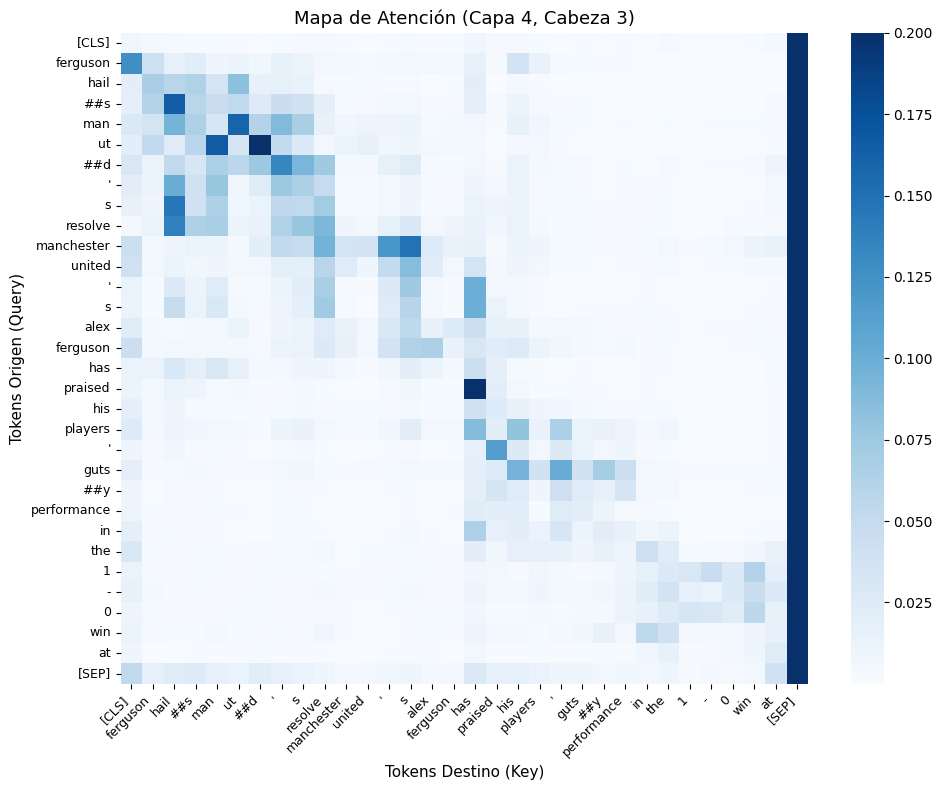

In [39]:
# Función de atención DistilBERT
# Supongamos que el índice del caso a analizar es el 1552
indice_elegido = 0  # o idx_correct

# 1. Extraer el texto limpio de la columna 'text'
ejemplo_texto = str(X_test['text'].iloc[indice_elegido])
# Tomar solo los primeros 20 tokens de la frase para la visualización
ejemplo_texto_corto = " ".join(ejemplo_texto.split()[:20])
plot_attention_head(
    model=model, 
    tokenizer=tokenizer, 
    text=ejemplo_texto_corto, 
    device=device, 
    layer_idx=4,  # Última capa
    head_idx=3     # Primera cabeza de atención (se puede probar con 0, 1, 2...)
)

## Conclusiones:

- El ajuste fino (fine-tuning) de DistilBERT mediante el entrenamiento, demostró una capacidad de generalización excepcional sobre el conjunto de prueba de la BBC. La combinación de la atención contextual de los Transformers con el optimizador AdamW permitió resolver con alta fidelidad las fronteras de decisión entre clases semánticamente cercanas (como tecnología y negocios), consolidando un modelo altamente confiable para la clasificación multiclase de textos periodísticos.

- La combinación de un codificador contextual profundo (DistilBERT) con una cabeza de clasificación lineal sobre el token [CLS] permite proyectar representaciones semánticas complejas en un espacio de probabilidad multiclase robusto, logrando la alta precisión global observada en la evaluación ($97.50\%$).


## Instanciación modelo RoBERTa

### Justificación del Uso de RoBERTa como Segundo Modelo

Con el propósito de evaluar el equilibrio entre eficiencia computacional y capacidad predictiva frente a DistilBERT, se implementó como segundo modelo a **RoBERTa** (`roberta-base`). La selección de esta arquitectura se fundamenta teóricamente en las optimizaciones metodológicas introducidas por [Liu et al., 2019 (arXiv:1907.11692)](https://arxiv.org/abs/1907.11692), destacando los siguientes aspectos clave aplicados al corpus de noticias:

* **Optimización rigurosa del pre-entrenamiento:** El estudio demuestra que el modelo BERT original estaba subentrenado; RoBERTa soluciona esto entrenándose durante más tiempo, con lotes masivos y sobre un corpus considerablemente más amplio, dotándolo de una capacidad representacional superior.
* **Enmascaramiento dinámico (*Dynamic Masking*):** A diferencia del enmascaramiento estático de BERT, RoBERTa genera patrones de enmascaramiento dinámicos en cada iteración, lo que mejora drásticamente la generalización y reduce el sobreajuste ante clases con alto traslape léxico (como *Business* y *Politics*).
* **Eliminación de la Predicción de Siguiente Oración (NSP):** Al prescindir de la tarea auxiliar de NSP, el modelo se enfoca puramente en un aprendizaje profundo de secuencias a nivel de bloques de texto, ideal para procesar artículos periodísticos completos.
* **Vocabulario BPE basado en bytes:** Utiliza un vocabulario ampliado (50,276 tokens), permitiendo manejar jerga técnica, acrónimos financieros y términos del sector tecnológico (*Tech*) de manera nativa sin incurrir en pérdida de información por tokens desconocidos.

In [40]:
#LIBERAR MEMORIA DE LA GPU ANTES DE CAMBIAR DE MODELO
import gc
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()
print("¡Memoria de DistilBERT liberada con éxito!")

¡Memoria de DistilBERT liberada con éxito!


### Instanciación del modelo RoBERTa

In [41]:
# 1. Cargar el tokenizador específico de RoBERTa
roberta_tokenizer = RobertaTokenizer.from_pretrained("roberta-base")

# 2. Instanciar el modelo para clasificación multiclase (5 clases)
roberta_model = RobertaForSequenceClassification.from_pretrained(
    "roberta-base", num_labels=5
)
roberta_model.to(device)

print("¡Modelo RoBERTa instanciado con éxito para comparación!")

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


¡Modelo RoBERTa instanciado con éxito para comparación!


In [42]:
print(roberta_model)

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
             

### Visualización resumen arquitectura del modelo

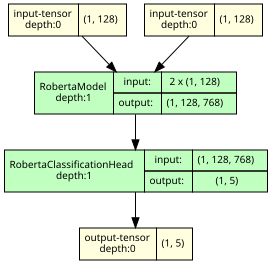

In [43]:
# 1. Asegurar modo evaluación en el modelo RoBERTa
roberta_model.eval()

# 2. Tensores de entrada sintéticos ajustados al vocabulario de RoBERTa (50276 tokens)
dummy_input_ids_rob = torch.randint(0, 50276, (1, 128), dtype=torch.long).to(device)
dummy_attention_mask_rob = torch.ones((1, 128), dtype=torch.long).to(device)

# 3. Construir el grafo del modelo RoBERTa
roberta_graph = draw_graph(
    roberta_model, 
    input_data=(dummy_input_ids_rob, dummy_attention_mask_rob),
    expand_nested=True,               # Expande los bloques internos del Transformer
    graph_name='Roberta_BBC',
    depth=1                           # Mantiene la estructura compacta y legible
)

# 4. EXPORTAR A PDF VECTORIAL PARA OVERLEAF
roberta_graph.visual_graph.render(
    filename='roberta_architecture', 
    format='pdf', 
    cleanup=True                       # Borra archivos temporales .gv
)

# 5. Mostrar el diagrama en el notebook de Jupyter/Colab
roberta_graph.visual_graph

### Resumen del flujo dimensional del modelo

| Componente | Operación | Dimensión de Salida | Descripción Funcional |
| :--- | :--- | :--- | :--- |
| **Entrada** | Tokenización (`input_ids` y `attention_mask`) | $(1, 128)$ | Lote de secuencias de texto procesadas y máscara de atención. |
| **RobertaModel** | Codificador base (Transformer) | $(1, 128, 768)$ | Procesamiento simultáneo de entradas para la extracción contextual profunda. |
| **RobertaClassificationHead** | Cabeza de clasificación especializada | $(1, 5)$ | Proyección de las características latentes a un espacio de 5 dimensiones. |
| **Salida** | Tensor de logits final | $(1, 5)$ | Generación de puntajes multiclase para las categorías del corpus periodístico. |

## Limpieza y preprocesamiento con tokenizador de RoBERTa

In [44]:
def preprocess_roberta_dataset(texts, tokenizer, max_len=None):
    """
    Función adaptada para limpiar y tokenizar usando el tokenizer oficial de RoBERTa.
    """
    # 1. Limpieza estandarizada de textos
    cleaned_texts = []
    for t in texts:
        text = str(t).lower()
        text = re.sub(r'<br\s*/?>', ' ', text)
        text = re.sub(r'https?://\S+|www\.\S+', '', text)
        # text = ct.fix(text) # Si usas contracciones
        text = re.sub(f'[{re.escape(string.punctuation)}]', ' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        cleaned_texts.append(text)
    
    # 2. Tokenizar usando el método oficial de Hugging Face (maneja padding y tokens especiales nativos)
    if max_len is None:
        # Calcular longitudes para el percentil 99 de forma automática
        token_lengths = [len(tokenizer.encode(t, add_special_tokens=True)) for t in cleaned_texts]
        max_percentile = int(np.percentile(token_lengths, 99))
        max_len = max(min(max_percentile, 512), 64)
        print(f"-> MAX_LEN seguro calculado automáticamente: {max_len}")

    # 3. Aplicar tokenización oficial con truncamiento y padding correcto para RoBERTa
    encodings = tokenizer(
        cleaned_texts,
        truncation=True,
        padding=True,
        max_length=max_len,
        return_tensors="pt"
    )
    
    return encodings['input_ids'], encodings['attention_mask'], max_len

In [45]:
# ==========================================
# PREPROCESAMIENTO Y DATALOADERS - RoBERTa
# ==========================================

# 1. Obtener los tensores con la función adaptada (usando el tokenizador oficial de RoBERTa)
X_train_padded_rob, train_masks_rob, max_len_train_rob = preprocess_roberta_dataset(X_train['text'], roberta_tokenizer, max_len=None)
X_val_padded_rob, val_masks_rob, _ = preprocess_roberta_dataset(X_val['text'], roberta_tokenizer, max_len=max_len_train_rob)
X_test_padded_rob, test_masks_rob, _ = preprocess_roberta_dataset(X_test['text'], roberta_tokenizer, max_len=max_len_train_rob)

# 2. Crear los TensorDatasets independientes para RoBERTa
train_dataset_rob = TensorDataset(
    torch.tensor(X_train_padded_rob, dtype=torch.long), 
    torch.tensor(train_masks_rob, dtype=torch.long), 
    torch.tensor(y_train_encoded, dtype=torch.long)
)

val_dataset_rob = TensorDataset(
    torch.tensor(X_val_padded_rob, dtype=torch.long), 
    torch.tensor(val_masks_rob, dtype=torch.long), 
    torch.tensor(y_val_encoded, dtype=torch.long)
)

test_dataset_rob = TensorDataset(
    torch.tensor(X_test_padded_rob, dtype=torch.long), 
    torch.tensor(test_masks_rob, dtype=torch.long), 
    torch.tensor(y_test_encoded, dtype=torch.long)
)

# 3. Crear los DataLoaders específicos para RoBERTa
train_loader_rob = DataLoader(train_dataset_rob, batch_size=16, shuffle=True)
val_loader_rob = DataLoader(val_dataset_rob, batch_size=16, shuffle=False)
test_loader_rob = DataLoader(test_dataset_rob, batch_size=16, shuffle=False)

print(f"-> DataLoaders de RoBERTa creados exitosamente con un MAX_LEN de {max_len_train_rob} tokens.")

Token indices sequence length is longer than the specified maximum sequence length for this model (543 > 512). Running this sequence through the model will result in indexing errors


-> MAX_LEN seguro calculado automáticamente: 512
-> DataLoaders de RoBERTa creados exitosamente con un MAX_LEN de 512 tokens.


## Entrenamiento del modelo RoBERTa

In [46]:
# ==========================================
# 1. CONFIGURACIÓN DE ENTRENAMIENTO (RoBERTa)
# ==========================================
optimizer = AdamW(roberta_model.parameters(), lr=2e-5, weight_decay=0.01)
n_epochs = 4          # 2 a 5 épocas es lo recomendado para fine-tuning
best_val_loss = float('inf')
best_model_state = None

history_roberta = {'loss': [], 'val_loss': []}
start = time.time()

print("Iniciando fine-tuning de RoBERTa para clasificación multi-clase...")

# ==========================================
# 2. BUCLE PRINCIPAL DE ENTRENAMIENTO
# ==========================================
for epoch in range(n_epochs):
    
    # --- Fase de entrenamiento ---
    roberta_model.train()
    running_loss = 0.0

    # Usar el DataLoader específico de RoBERTa
    for xb, mask_b, yb in train_loader_rob:
        xb, mask_b, yb = xb.to(device), mask_b.to(device), yb.to(device)

        optimizer.zero_grad()
        
        # RoBERTa utiliza los mismos argumentos de entrada
        outputs = roberta_model(input_ids=xb, attention_mask=mask_b)
        logits = outputs.logits  
        
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    # Calcular pérdida media usando el tamaño del dataset de RoBERTa
    train_loss = running_loss / len(train_dataset_rob)

    # --- Fase de validación ---
    roberta_model.eval()
    val_running_loss = 0.0

    with torch.no_grad():
        # Usar el DataLoader de validación de RoBERTa
        for v_xb, v_mask_b, v_yb in val_loader_rob:
            v_xb, v_mask_b, v_yb = v_xb.to(device), v_mask_b.to(device), v_yb.to(device)

            outputs = roberta_model(input_ids=v_xb, attention_mask=v_mask_b)
            val_logits = outputs.logits
            
            loss = criterion(val_logits, v_yb)
            val_running_loss += loss.item() * v_xb.size(0)

    # Calcular pérdida de validación usando el dataset de RoBERTa
    val_loss = val_running_loss / len(val_dataset_rob)

    # Guardar historial específico para RoBERTa
    history_roberta['loss'].append(train_loss)
    history_roberta['val_loss'].append(val_loss)

    print(f"Época {epoch+1}/{n_epochs} - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

    # Guardar automáticamente el mejor modelo de estas épocas
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(roberta_model.state_dict())
        print(" -> ¡Nuevo mejor modelo de RoBERTa guardado!")

# Restaurar los mejores pesos encontrados
if best_model_state is not None:
    roberta_model.load_state_dict(best_model_state)

print(f"Entrenamiento de RoBERTa finalizado en {time.time() - start:.2f} segundos.")

Iniciando fine-tuning de RoBERTa para clasificación multi-clase...
Época 1/4 - loss: 0.4890 - val_loss: 0.0590
 -> ¡Nuevo mejor modelo de RoBERTa guardado!
Época 2/4 - loss: 0.0851 - val_loss: 0.1880
Época 3/4 - loss: 0.0507 - val_loss: 0.0851
Época 4/4 - loss: 0.0257 - val_loss: 0.0541
 -> ¡Nuevo mejor modelo de RoBERTa guardado!
Entrenamiento de RoBERTa finalizado en 334.12 segundos.


### Visualización de la función de pérdida a lo largo del entrenamiento

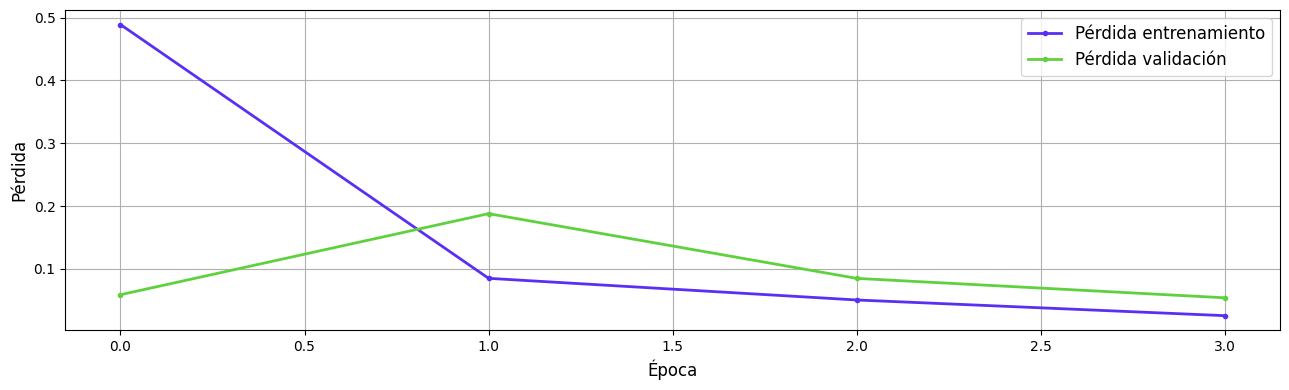

In [47]:
visualization_history(history_roberta)

## Evaluación del modelo con conjunto de prueba

=== REPORTE DE CLASIFICACIÓN - ROBERTA ===
               precision    recall  f1-score   support

     business     0.9867    0.9737    0.9801        76
entertainment     0.9636    0.9636    0.9636        55
     politics     0.9833    0.9672    0.9752        61
        sport     1.0000    1.0000    1.0000        76
         tech     0.9630    1.0000    0.9811        52

     accuracy                         0.9812       320
    macro avg     0.9793    0.9809    0.9800       320
 weighted avg     0.9814    0.9812    0.9812       320



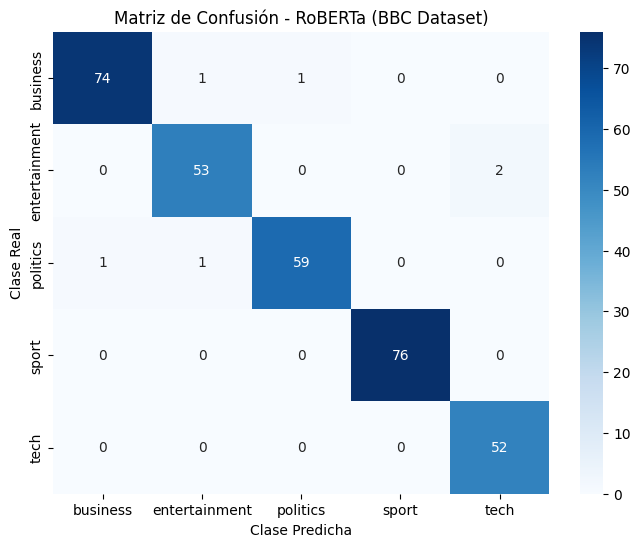

In [48]:
# ==========================================
# EVALUACIÓN DEL MODELO RoBERTa
# ==========================================

roberta_model.eval()
all_preds_ra = []
all_targets_ra = []

with torch.no_grad():
    for xb, mask_b, yb in test_loader_rob:
        xb, mask_b = xb.to(device), mask_b.to(device)
        
        # Inferencia con RoBERTa pasando tokens y máscaras
        outputs = roberta_model(input_ids=xb, attention_mask=mask_b)
        logits = outputs.logits
        
        # Extraer la clase con mayor probabilidad (argmax)
        preds = torch.argmax(logits, dim=-1)
        
        all_preds_ra.extend(preds.cpu().numpy())
        all_targets_ra.extend(yb.numpy())

# 1. Reporte detallado de métricas por categoría
report_ra = classification_report(all_targets_ra, all_preds_ra, target_names=le.classes_, digits=4)
print("=== REPORTE DE CLASIFICACIÓN - ROBERTA ===")
print(report_ra)

# 2. Matriz de Confusión para análisis visual de errores
conf_matrix_ra = confusion_matrix(all_targets_ra, all_preds_ra)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_ra, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Real')
plt.title('Matriz de Confusión - RoBERTa (BBC Dataset)')
plt.show()

### Análisis cualitativo del modelo

In [49]:
# Llamada a la función con el modelo RoBERTa actual
analyze_model_predictions(
    model=roberta_model, 
    test_loader=test_loader_rob, 
    device=device, 
    class_names=le.classes_, 
    X_test=X_test
)

Ejecutando inferencia en el conjunto de prueba...

🟢 CASO ACERTADO
Texto (extracto): text    Ferguson hails Man Utd's resolve\n\nManchester...
Name: 1552, dtype: object...

• Categoría Real:      sport
• Categoría Predicha:  sport

🔴 CASO FALLIDO (ERROR)
Texto (extracto): text    Making your office work for you\n\nOur mission...
Name: 241, dtype: object...

• Categoría Real:      business
• Categoría Predicha:  entertainment


## Comparación de métricas de los dos modelos.

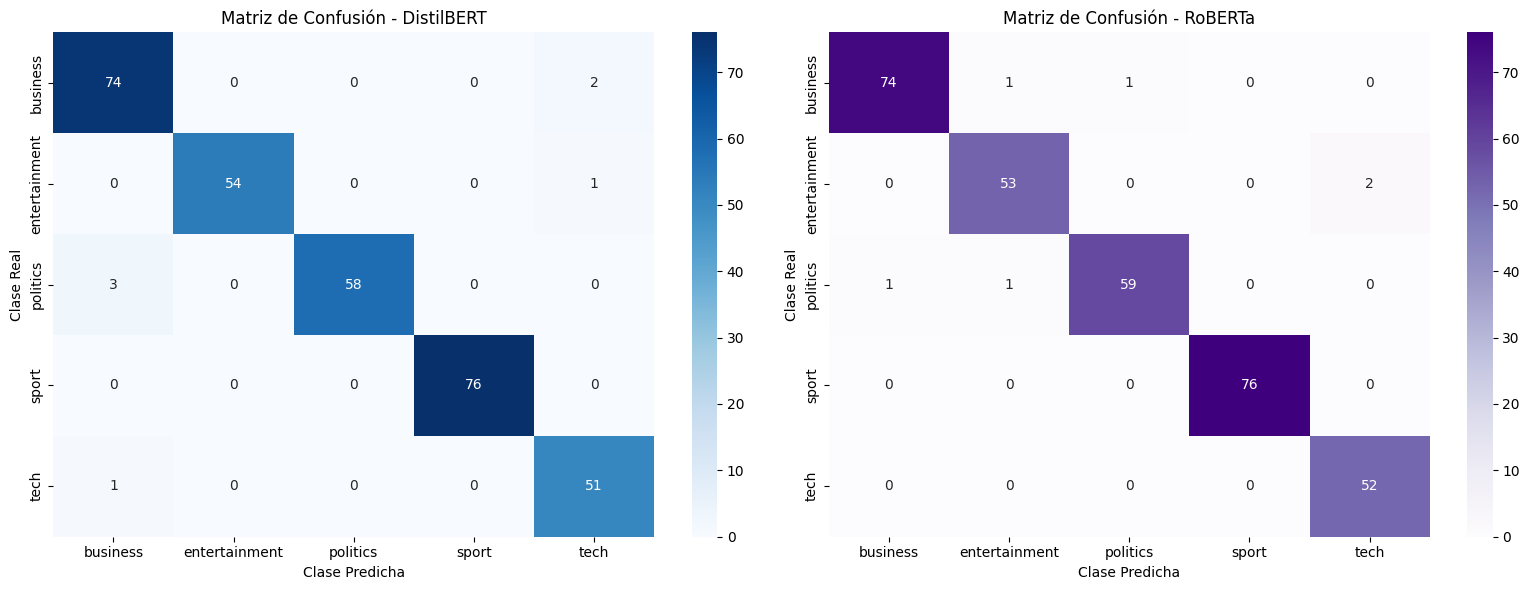

=== TABLA COMPARATIVA DE REPORTES DE CLASIFICACIÓN ===


,Precisión (DistilBERT),Precisión (RoBERTa),Recall (DistilBERT),Recall (RoBERTa),F1-Score (DistilBERT),F1-Score (RoBERTa)
Categoría,,,,,,
business,0.9487,0.9867,0.9737,0.9737,0.9610,0.9801
entertainment,1.0000,0.9636,0.9818,0.9636,0.9908,0.9636
politics,1.0000,0.9833,0.9508,0.9672,0.9748,0.9752
sport,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
tech,0.9444,0.9630,0.9808,1.0000,0.9623,0.9811



=== CÓDIGO LATEX PARA COPIAR ===
\begin{table}
\centering
\caption{Comparativa de métricas por categoría entre DistilBERT y RoBERTa.}
\label{tab:comparacion_modelos}
\begin{tabular}{lrrrrrr}
\toprule
{} &  Precisión (DistilBERT) &  Precisión (RoBERTa) &  Recall (DistilBERT) &  Recall (RoBERTa) &  F1-Score (DistilBERT) &  F1-Score (RoBERTa) \\
Categoría     &                         &                      &                      &                   &                        &                     \\
\midrule
business      &                  0.9487 &               0.9867 &               0.9737 &            0.9737 &                 0.9610 &              0.9801 \\
entertainment &                  1.0000 &               0.9636 &               0.9818 &            0.9636 &                 0.9908 &              0.9636 \\
politics      &                  1.0000 &               0.9833 &               0.9508 &            0.9672 &                 0.9748 &              0.9752 \\
sport         &      

In [50]:
# ==========================================
# 1. MATRICES DE CONFUSIÓN LADO A LADO
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz DistilBERT
sns.heatmap(conf_matrix_db, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title('Matriz de Confusión - DistilBERT')
axes[0].set_xlabel('Clase Predicha')
axes[0].set_ylabel('Clase Real')

# Matriz RoBERTa
sns.heatmap(conf_matrix_ra, annot=True, fmt='d', cmap='Purples', 
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Matriz de Confusión - RoBERTa')
axes[1].set_xlabel('Clase Predicha')
axes[1].set_ylabel('Clase Real')

plt.tight_layout()
plt.show()


# ==========================================
# 2. TABLA COMPARATIVA DE REPORTES (Pandas)
# ==========================================
# Extraer diccionarios de los reportes ya calculados
rep_db = classification_report(all_targets_db, all_preds_db, target_names=le.classes_, output_dict=True)
rep_ra = classification_report(all_targets_ra, all_preds_ra, target_names=le.classes_, output_dict=True)

# Construir filas comparativas por categoría
comparison_rows = []
for cat in le.classes_:
    comparison_rows.append({
        'Categoría': cat,
        'Precisión (DistilBERT)': rep_db[cat]['precision'],
        'Precisión (RoBERTa)': rep_ra[cat]['precision'],
        'Recall (DistilBERT)': rep_db[cat]['recall'],
        'Recall (RoBERTa)': rep_ra[cat]['recall'],
        'F1-Score (DistilBERT)': rep_db[cat]['f1-score'],
        'F1-Score (RoBERTa)': rep_ra[cat]['f1-score'],
    })

# Añadir métricas globales (Accuracy y promedios)
df_reports_comparison = pd.DataFrame(comparison_rows)
df_reports_comparison.set_index('Categoría', inplace=True)

print("=== TABLA COMPARATIVA DE REPORTES DE CLASIFICACIÓN ===")
display(df_reports_comparison.round(4))

#Generar e imprimir el código LaTeX para Overleaf
print("\n=== CÓDIGO LATEX PARA COPIAR ===")
latex_code = df_reports_comparison.round(4).to_latex(
    index=True, 
    caption="Comparativa de métricas por categoría entre DistilBERT y RoBERTa.", 
    label="tab:comparacion_modelos"
)
print(latex_code)

### Metricas globales

In [51]:
# 1. Extraer métricas globales de los diccionarios de reportes
metrics_global = {
    'Métrica Global': ['Accuracy', 'F1-Score (Macro Avg)', 'F1-Score (Weighted Avg)'],
    'DistilBERT': [
        rep_db['accuracy'],
        rep_db['macro avg']['f1-score'],
        rep_db['weighted avg']['f1-score']
    ],
    'RoBERTa': [
        rep_ra['accuracy'],
        rep_ra['macro avg']['f1-score'],
        rep_ra['weighted avg']['f1-score']
    ]
}

# 2. Crear y estilizar el DataFrame
df_global_comparison = pd.DataFrame(metrics_global)
df_global_comparison.set_index('Métrica Global', inplace=True)

print("=== TABLA COMPARATIVA DE MÉTRICAS GLOBALES ===")
display(df_global_comparison.round(4))
print(df_global_comparison.round(4).to_latex())

=== TABLA COMPARATIVA DE MÉTRICAS GLOBALES ===


,DistilBERT,RoBERTa
Métrica Global,,
Accuracy,0.9781,0.9812
F1-Score (Macro Avg),0.9778,0.9800
F1-Score (Weighted Avg),0.9782,0.9812


\begin{tabular}{lrr}
\toprule
{} &  DistilBERT &  RoBERTa \\
Métrica Global          &             &          \\
\midrule
Accuracy                &      0.9781 &   0.9812 \\
F1-Score (Macro Avg)    &      0.9778 &   0.9800 \\
F1-Score (Weighted Avg) &      0.9782 &   0.9812 \\
\bottomrule
\end{tabular}



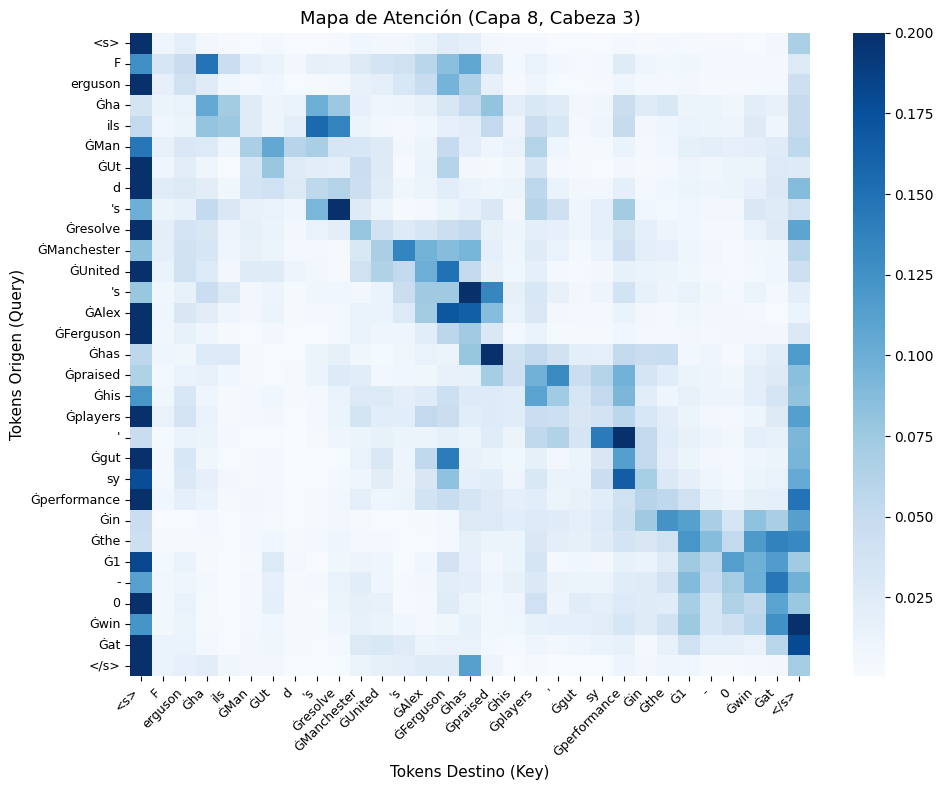

In [52]:
# Supongamos que el índice del caso a analizar es el 1552
indice_elegido = 0  # o idx_correct

# 1. Extraer el texto limpio de la columna 'text'
ejemplo_texto = str(X_test['text'].iloc[indice_elegido])
# Tomar solo los primeros 20 tokens de la frase para la visualización
ejemplo_texto_corto = " ".join(ejemplo_texto.split()[:20])
# 2. Pasarlo directamente a la función de atención de RoBERTa
plot_attention_head(
    model=roberta_model, 
    tokenizer=roberta_tokenizer, 
    text=ejemplo_texto_corto, 
    device=device, 
    layer_idx=8,  # Última capa
    head_idx=3     # Primera cabeza de atención (se puede probar con 0, 1, 2...)
)